In [1]:
# Artificial Intelligence
# Lab 9

In [2]:
import numpy as np 
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
df = pd.read_excel('Z-Alizadeh sani dataset.xlsx')

In [4]:
print(df.head())

   Age  Weight  Length    Sex        BMI  DM  HTN  Current Smoker  EX-Smoker  \
0   53      90     175   Male  29.387755   0    1               1          0   
1   67      70     157  Fmale  28.398718   0    1               0          0   
2   54      54     164   Male  20.077335   0    0               1          0   
3   66      67     158  Fmale  26.838648   0    1               0          0   
4   50      87     153  Fmale  37.165193   0    1               0          0   

   FH  ...    K   Na    WBC Lymph Neut  PLT EF-TTE  Region RWMA     VHD  \
0   0  ...  4.7  141   5700    39   52  261     50            0       N   
1   0  ...  4.7  156   7700    38   55  165     40            4       N   
2   0  ...  4.7  139   7400    38   60  230     40            2    mild   
3   0  ...  4.4  142  13000    18   72  742     55            0  Severe   
4   0  ...  4.0  140   9200    55   39  274     50            0  Severe   

     Cath  
0     Cad  
1     Cad  
2     Cad  
3  Normal  
4  Norma

In [5]:
print(df.describe())

              Age      Weight      Length         BMI          DM         HTN  \
count  303.000000  303.000000  303.000000  303.000000  303.000000  303.000000   
mean    58.897690   73.831683  164.716172   27.248339    0.297030    0.590759   
std     10.392278   11.987358    9.327661    4.098865    0.457706    0.492507   
min     30.000000   48.000000  140.000000   18.115413    0.000000    0.000000   
25%     51.000000   65.000000  158.000000   24.514380    0.000000    0.000000   
50%     58.000000   74.000000  165.000000   26.775510    0.000000    1.000000   
75%     66.000000   81.000000  171.000000   29.411765    1.000000    1.000000   
max     86.000000  120.000000  188.000000   40.900658    1.000000    1.000000   

       Current Smoker   EX-Smoker          FH          BP  ...         ESR  \
count      303.000000  303.000000  303.000000  303.000000  ...  303.000000   
mean         0.207921    0.033003    0.158416  129.554455  ...   19.462046   
std          0.406491    0.178941   

In [6]:
df['Cath'] = df['Cath'].map({
    'Normal' : 0,
    'Cad' : 1
})

In [7]:
numeric_df = df.select_dtypes(include=['number'])

In [8]:
print(numeric_df.head())

   Age  Weight  Length        BMI  DM  HTN  Current Smoker  EX-Smoker  FH  \
0   53      90     175  29.387755   0    1               1          0   0   
1   67      70     157  28.398718   0    1               0          0   0   
2   54      54     164  20.077335   0    0               1          0   0   
3   66      67     158  26.838648   0    1               0          0   0   
4   50      87     153  37.165193   0    1               0          0   0   

    BP  ...    HB    K   Na    WBC  Lymph  Neut  PLT  EF-TTE  Region RWMA  \
0  110  ...  15.6  4.7  141   5700     39    52  261      50            0   
1  140  ...  13.9  4.7  156   7700     38    55  165      40            4   
2  100  ...  13.5  4.7  139   7400     38    60  230      40            2   
3  100  ...  12.1  4.4  142  13000     18    72  742      55            0   
4  110  ...  13.2  4.0  140   9200     55    39  274      50            0   

   Cath  
0     1  
1     1  
2     1  
3     0  
4     0  

[5 rows x 35 

In [9]:
target_corr = numeric_df.corr()['Cath'].sort_values(ascending=False)

In [10]:
print(target_corr)

Cath                  1.000000
Typical Chest Pain    0.542967
Age                   0.357247
Region RWMA           0.316011
HTN                   0.287761
DM                    0.252897
BP                    0.237762
Tinversion            0.236933
FBS                   0.205553
K                     0.181320
ESR                   0.178447
PR                    0.168366
Q Wave                0.149848
St Depression         0.144426
TG                    0.140593
St Elevation          0.139684
Neut                  0.124086
Function Class        0.097087
BUN                   0.088903
CR                    0.086758
Current Smoker        0.073504
WBC                   0.070830
Edema                 0.054069
FH                    0.035605
EX-Smoker             0.035578
Length                0.001024
LDL                  -0.023535
HB                   -0.042416
HDL                  -0.042587
Weight               -0.066833
BMI                  -0.078189
Na                   -0.084982
PLT     

In [11]:
target_corr_filtered = target_corr.drop('Cath')

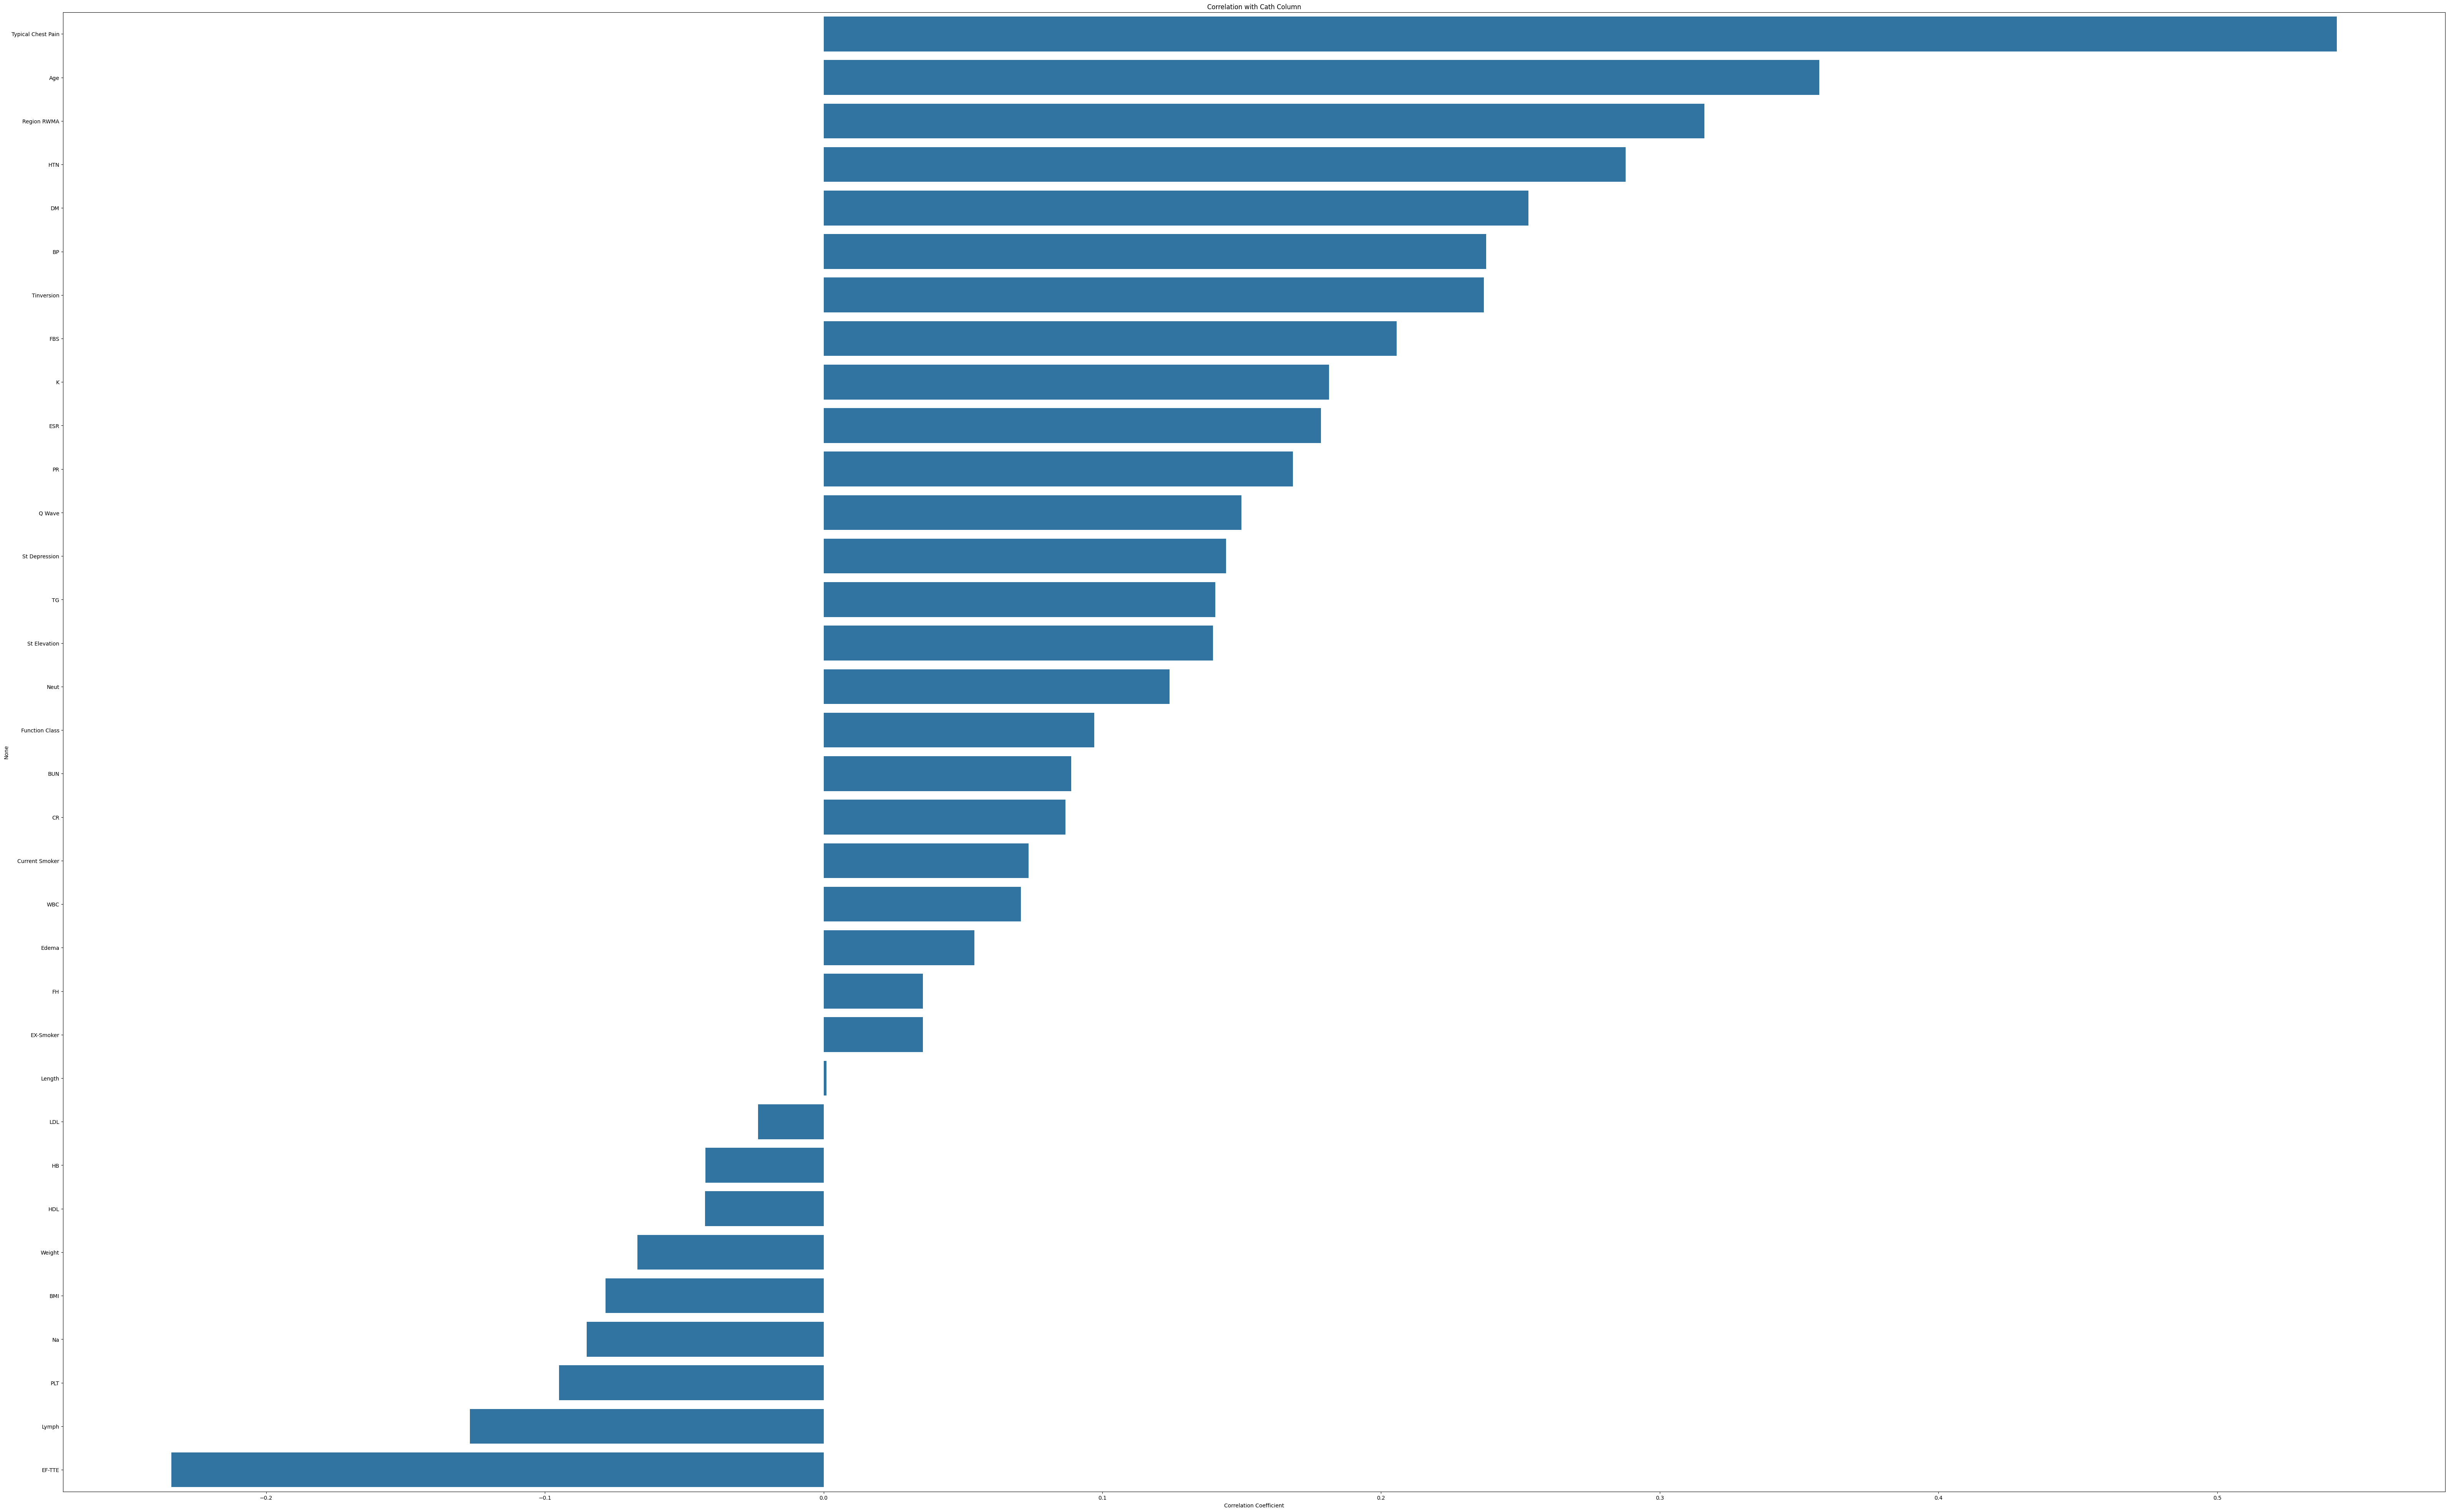

In [12]:
plt.figure(figsize=(80, 50))

sns.barplot(x= target_corr_filtered.values, y= target_corr_filtered.index)
plt.title('Correlation with Cath Column')
plt.xlabel('Correlation Coefficient')
plt.show()